In [1]:
import numpy as np
from matplotlib import pyplot as plt
import matplotlib.patches as patches
import pickle
import sys
sys.path.insert(0,'../src/')



from utils import *
from multiply_connected_pipe import *
from pipe_system import PipeSystem
from abstract_pipe import *
from curve import *
from multiply_connected_pipe.t_shaped import TShaped

# Set up plotting parameters
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 12


#### geometry creation

In [2]:
# Goal 1: Create T-shaped and L-shaped pipe junctions

print("Creating 十-shaped pipe junctions...")


ls = np.array([
    [10,0],
    [0,10],
    [-10,0],
    [0,-10],
])

rs = np.array([1,1,1,1])

corner_size = 1
cross_shaped = NLets(ls,rs,corner_size)
t_shaped = TShaped(10,1,corner_size)


eps = 1e-8
cross_shaped.build_geometry(required_tol=eps)
t_shaped.build_geometry(required_tol=eps)

print(f"十-pipe: {t_shaped.n_pts} boundary points")
print(f"T-pipe: {t_shaped.n_pts} boundary points")

Creating 十-shaped pipe junctions...
1
1
1
1
1
1
十-pipe: 3180 boundary points
T-pipe: 3180 boundary points


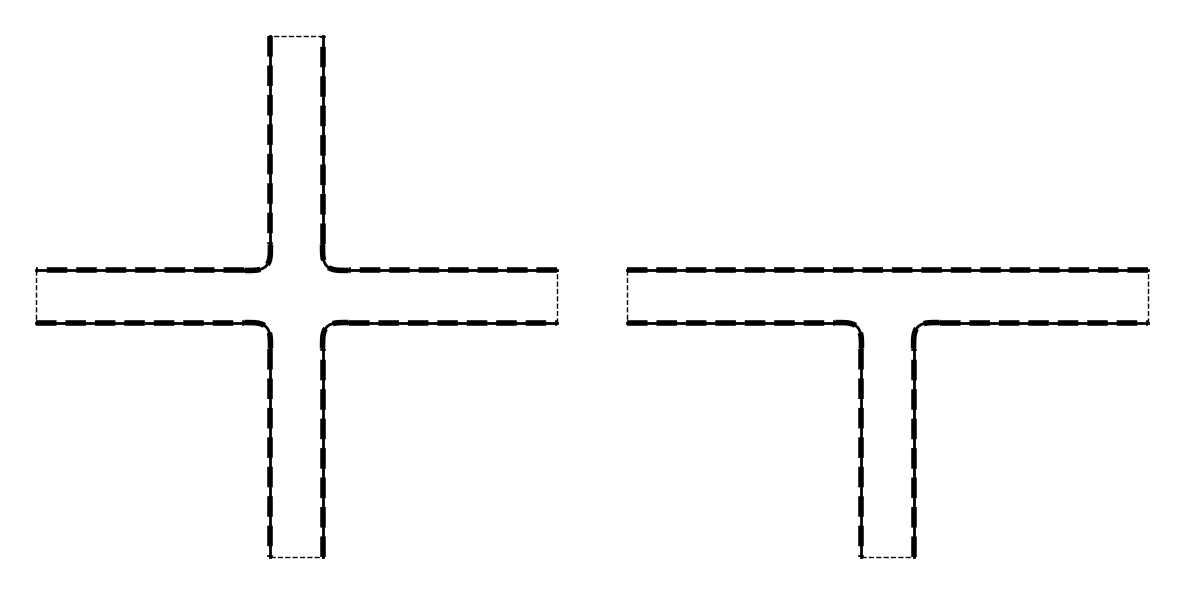

In [3]:
# Visualize the pipe geometries using the boundary plotting method
fig, axes = plt.subplots(1,2,tight_layout=True,sharey=True)

# Plot T-shaped pipe
axes[0].set_aspect('equal')
axes[0].axis('off')
cross_shaped.exterior_boundary.plot_plyg_bdr(axes[0],color='k')

axes[1].set_aspect('equal')
axes[1].axis('off')
t_shaped.exterior_boundary.plot_plyg_bdr(axes[1],color='k')

plt.show()

In [4]:
# Goal 2: Solve for characteristic flows with Poiseuille boundary conditions
print("Building complete solver for T-shaped pipes...")
# Build complete solvers - this includes geometry, matrices, and flow solutions
eps = 1e-8
cross_shaped.build(required_tol=eps, fmm=True, density=20)
t_shaped.build(required_tol=eps, fmm=True, density=20)

Building complete solver for T-shaped pipes...





/Users/haiy/git/fmm2d/python/fmm2dpy/fmm2d.py:894: ComplexWarning: Casting complex values to real discards the imaginary part
  out.pottarg,out.gradtarg,out.ier = lfmm.cfmm2d_t_d_g(eps,sources,dipstr,targets)


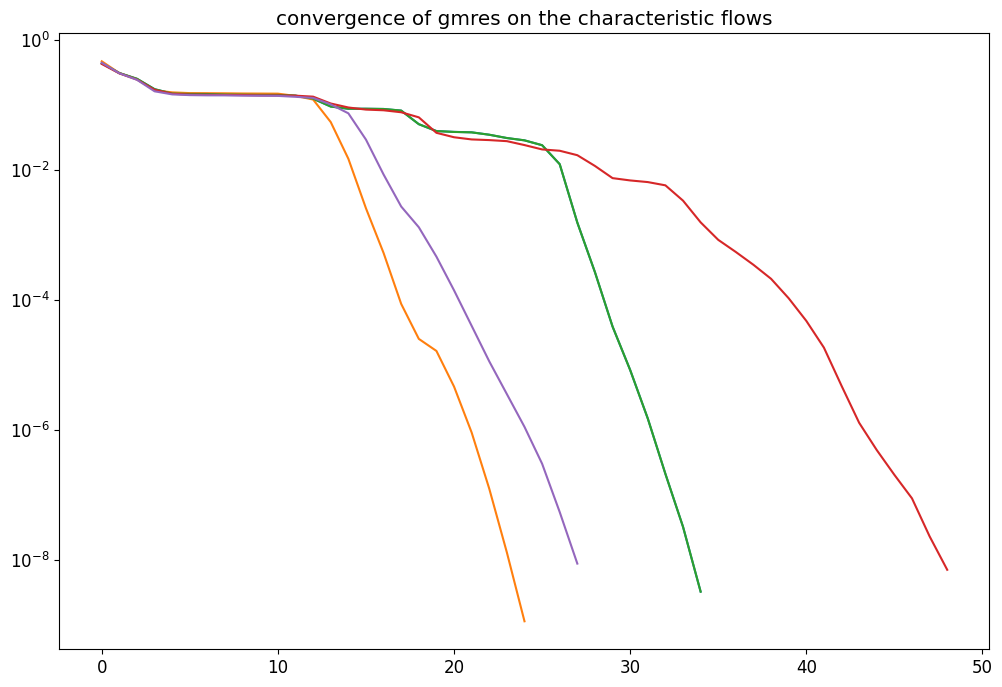

In [5]:
for c in cross_shaped.callbacks:
    plt.semilogy(c.residuals)
    
for c in t_shaped.callbacks:
    plt.semilogy(c.residuals)
    
plt.title('convergence of gmres on the characteristic flows')
plt.show()

#### flows 

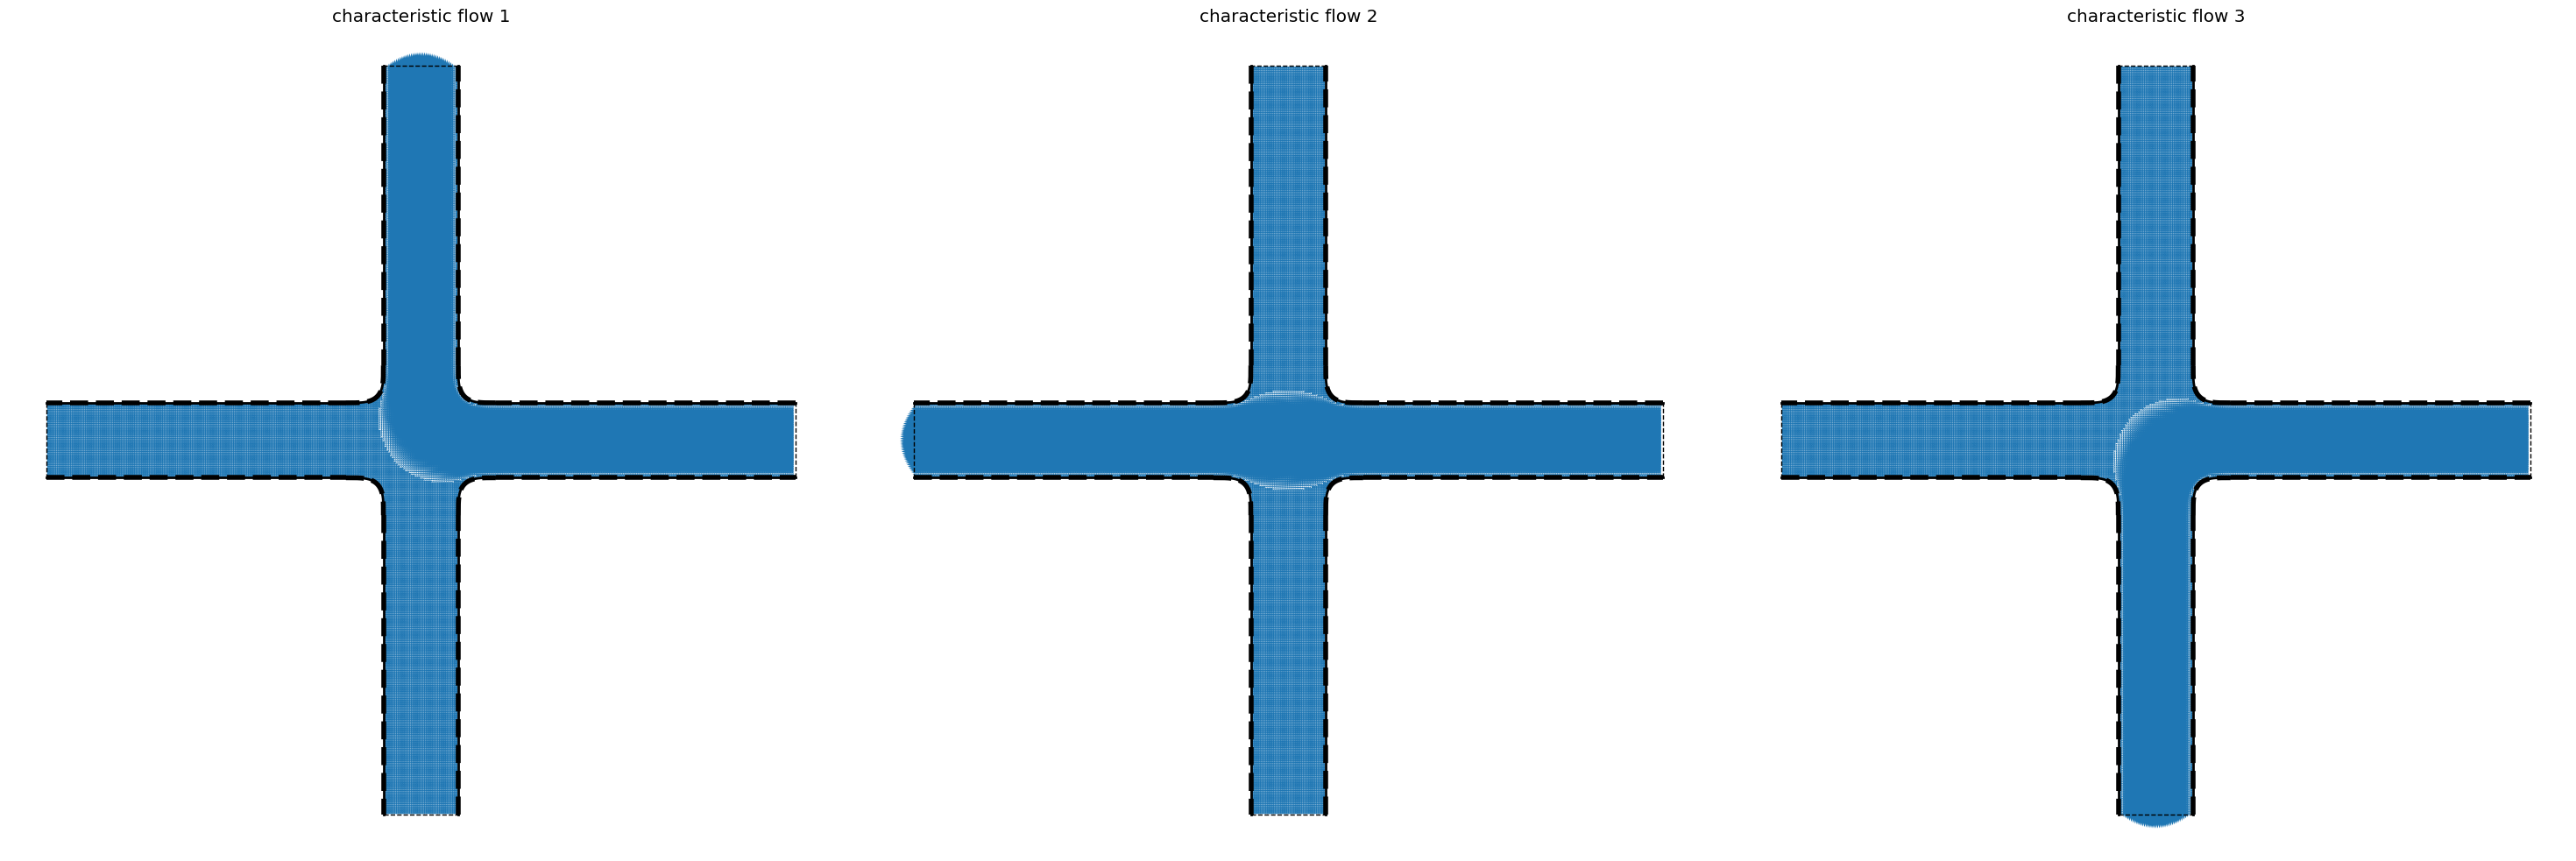

In [9]:
xs = cross_shaped.xs
ys = cross_shaped.ys

fig, axes = plt.subplots(1,cross_shaped.n_flows, figsize=(10*cross_shaped.n_flows,10),tight_layout=True)

for i in range(cross_shaped.n_flows):
    axes[i].set_aspect('equal')
    axes[i].axis('off')
    axes[i].set_title(f'characteristic flow {i+1}')
    
    u,v,p,o = cross_shaped.fields_with_fluxes(np.eye(cross_shaped.n_flows)[i],0,0)
    cross_shaped.exterior_boundary.plot_plyg_bdr(axes[i], color='k')
    axes[i].quiver(xs, ys, u, v, scale=40, color='C0', width=0.003)

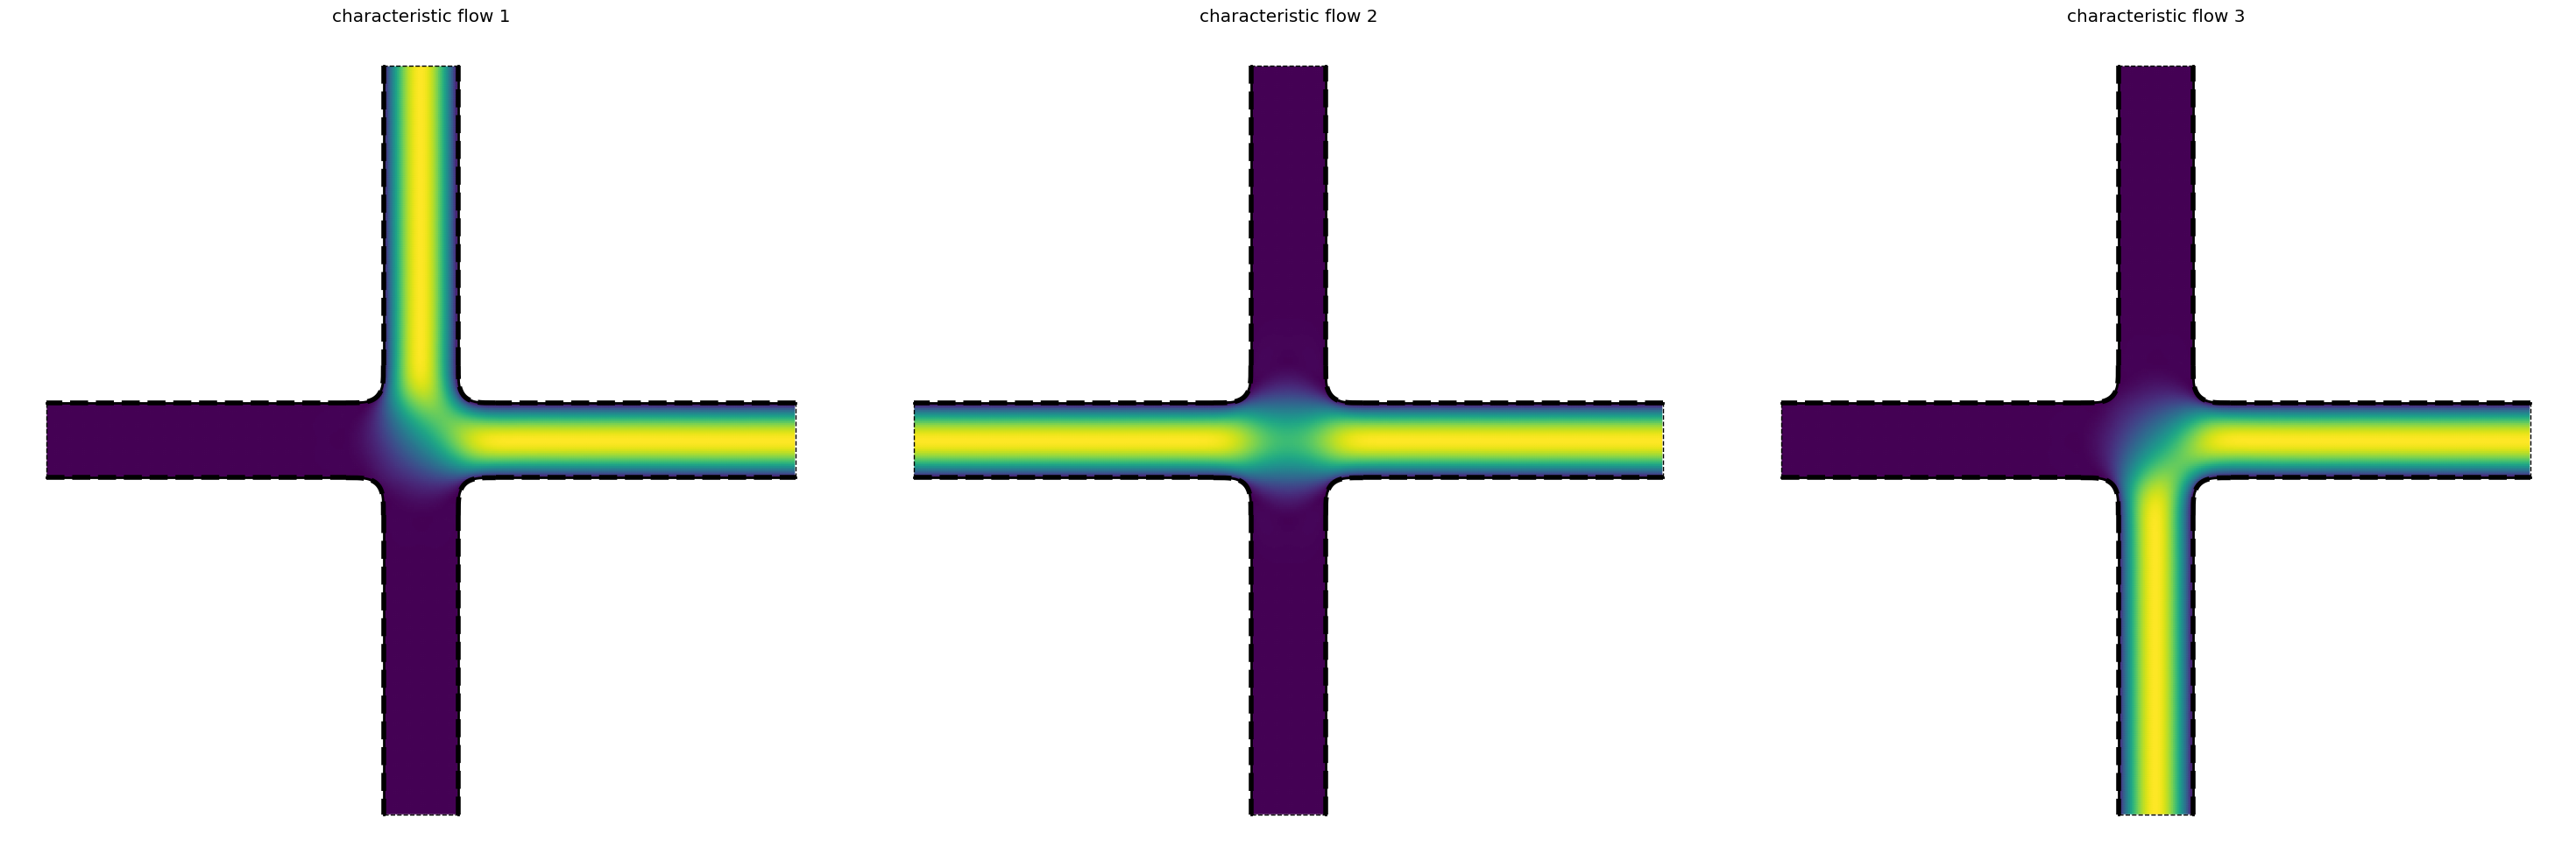

In [11]:
xs = cross_shaped.xs
ys = cross_shaped.ys

fig, axes = plt.subplots(1,cross_shaped.n_flows, figsize=(10*cross_shaped.n_flows,10),tight_layout=True)

for i in range(cross_shaped.n_flows):
    axes[i].set_aspect('equal')
    axes[i].axis('off')
    axes[i].set_title(f'characteristic flow {i+1}')
    
    u,v,p,o = cross_shaped.fields_with_fluxes(np.eye(cross_shaped.n_flows)[i],0,0)
    cross_shaped.exterior_boundary.plot_plyg_bdr(axes[i], color='k')
    axes[i].scatter(xs, ys, c=np.linalg.norm(np.array([u,v]),axis=0),s=2)

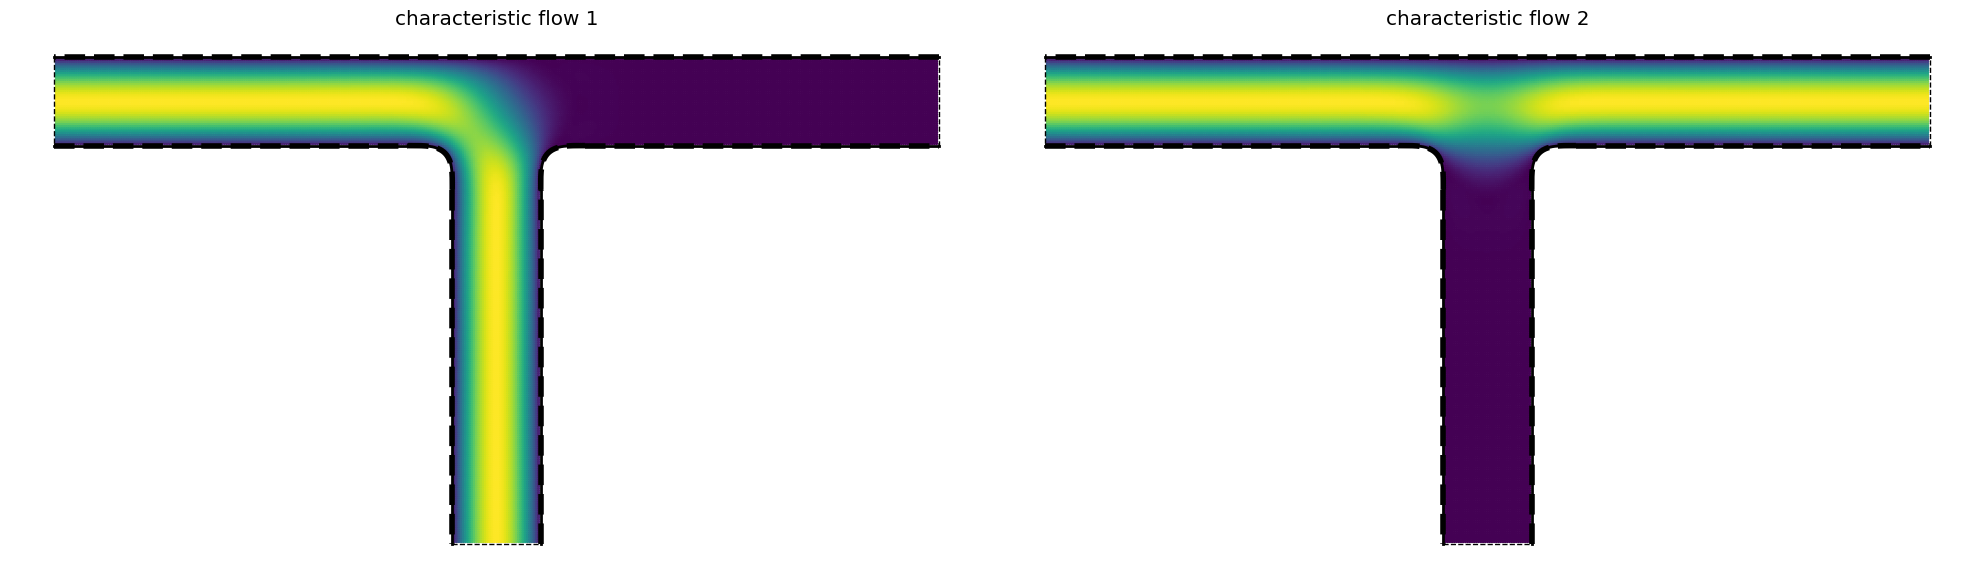

In [12]:
xs = t_shaped.xs
ys = t_shaped.ys

fig, axes = plt.subplots(1,t_shaped.n_flows, figsize=(10*t_shaped.n_flows,10),tight_layout=True)

for i in range(t_shaped.n_flows):
    axes[i].set_aspect('equal')
    axes[i].axis('off')
    axes[i].set_title(f'characteristic flow {i+1}')
    
    u,v,p,o = t_shaped.fields_with_fluxes(np.eye(t_shaped.n_flows)[i],0,0)
    t_shaped.exterior_boundary.plot_plyg_bdr(axes[i], color='k')
    axes[i].scatter(xs, ys, c=np.linalg.norm(np.array([u,v]),axis=0),s=2)

#### assembling the pipes

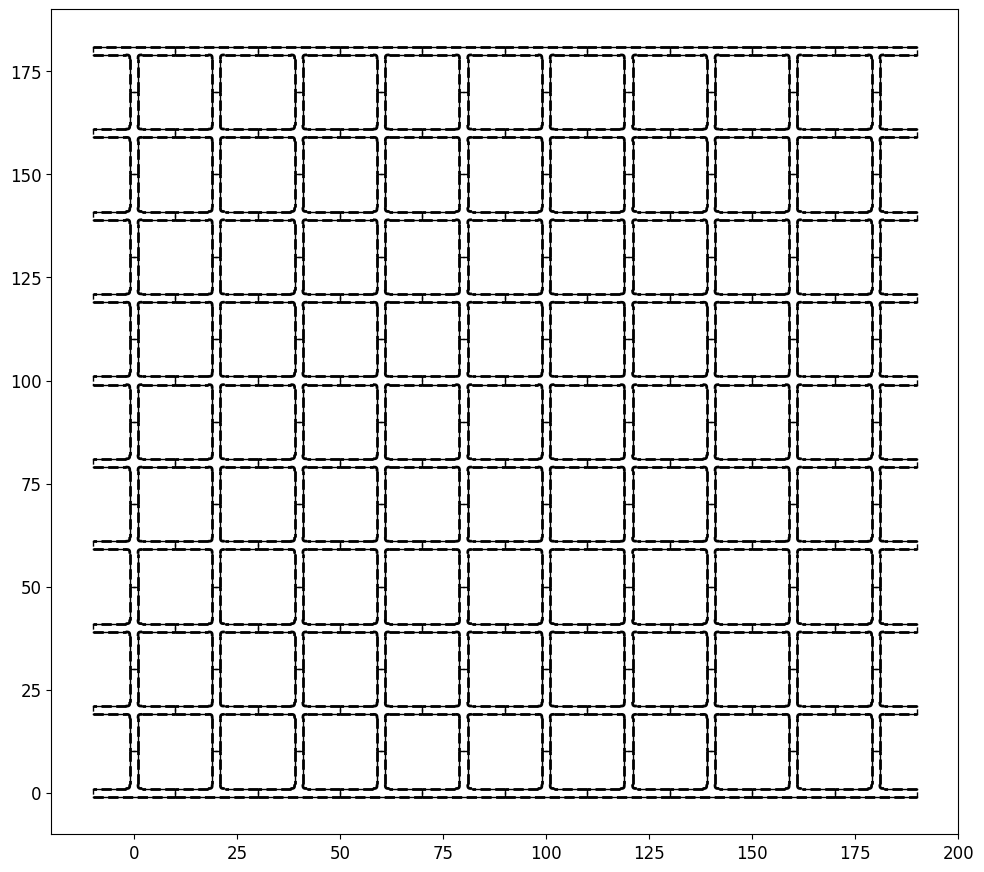

In [ ]:
fig,ax = plt.subplots(figsize=(10,10),tight_layout=True)

n_rep_x = 10
n_rep_y = 10


pipes = [RealPipe(cross_shaped,20*i,20*j,0) \
    for i in range(n_rep_x) \
    for j in range(1,n_rep_y-1)] + \
        [RealPipe(t_shaped,20*i,20*0,np.pi) for i in range(n_rep_x)] + \
        [RealPipe(t_shaped,20*i,20*(n_rep_y-1),0) for i in range(n_rep_x)]


for i,pipe in enumerate(pipes):
    pipe.plot_plyg_bdr(ax)
    # x = np.mean(pipe.xs) - 0.5
    # y = np.mean(pipe.ys) - 0.5
    # ax.text(x,y,f'{i}',fontsize=10)

ax.set_aspect('equal')
# ax.axis('off')
plt.show()

In [26]:
import pickle

with open('pipe.pkl', 'wb') as f:
    pickle.dump([cross_shaped,t_shaped], f)


In [ ]:
import pickle

with open('pipe.pkl', 'rb') as f:
    cross_shaped = pickle.load(f)
